# Model

Sections 7–18. Reads `output/Tetouan_hourly_clean.csv` when needed, fits the forecast models, and writes `output/model_evaluation.json` plus `models/final_forecast_models.pkl`.


In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
VC_RED = "#D71920"
VC_DARK = "#8B1014"
ZONE_COLORS = ["#D71920", "#4C78A8", "#59A14F"]
zone_cols = ["zone_1_power", "zone_2_power", "zone_3_power"]
weather_cols = [
    "temperature", "humidity", "wind_speed",
    "general_diffuse_flows", "diffuse_flows",
]

if "df_hourly" not in globals():
    df_hourly = (
        pd.read_csv(Path("output") / "Tetouan_hourly_clean.csv", parse_dates=["datetime"])
        .set_index("datetime")
    )


# 7. Feature Engineering Provides 1 Hour Forecast

## Time Conventions

Each line at $t$ time uses observed data until the end of [[ph1]] hours to forecast the load of $t+1$ hours:

$$
\text{features at } t \longrightarrow \text{target at } t+1
$$

Conse-

- `total_power` at $t$ is allowed.
- Rolling features can include $t$.
- Calendar features must describe `forecast_time = t + 1 hour`.
- Weather at $t+1$ is not used, unless it is a true weather forecast available at $t$.

The sine and cosine variables were created to represent periodic time characteristics such as:
- Time of day: after 23:00 back to 00:00.
- Weekday: after Sunday back to Monday.
- Month of the year: after December back to January.
If only integer time variables are included in the model, the model does not see the "beginning of the cycle near the end of the cycle" relationship directly.

In [ ]:
df_fe = df_hourly.copy()

df_fe["forecast_time"] = df_fe.index + pd.Timedelta(hours=1)
df_fe["target_t_plus_1"] = df_fe["total_power"].shift(-1)

# Calendar features of when to forecast t+1
forecast_dt = df_fe["forecast_time"]
df_fe["forecast_hour"] = forecast_dt.dt.hour
df_fe["forecast_day_of_week"] = forecast_dt.dt.dayofweek
df_fe["forecast_day_of_month"] = forecast_dt.dt.day
df_fe["forecast_day_of_year"] = forecast_dt.dt.dayofyear
df_fe["forecast_week_of_year"] = forecast_dt.dt.isocalendar().week.astype(int)
df_fe["forecast_month"] = forecast_dt.dt.month
df_fe["forecast_quarter"] = forecast_dt.dt.quarter
df_fe["forecast_is_weekend"] = forecast_dt.dt.dayofweek.isin([5, 6]).astype(int)

# Cyclical encoding
df_fe["forecast_hour_sin"] = np.sin(2 * np.pi * df_fe["forecast_hour"] / 24)
df_fe["forecast_hour_cos"] = np.cos(2 * np.pi * df_fe["forecast_hour"] / 24)
df_fe["forecast_dow_sin"] = np.sin(2 * np.pi * df_fe["forecast_day_of_week"] / 7)
df_fe["forecast_dow_cos"] = np.cos(2 * np.pi * df_fe["forecast_day_of_week"] / 7)
df_fe["forecast_month_sin"] = np.sin(2 * np.pi * (df_fe["forecast_month"] - 1) / 12)
df_fe["forecast_month_cos"] = np.cos(2 * np.pi * (df_fe["forecast_month"] - 1) / 12)

calendar_features = [
    "forecast_hour", "forecast_day_of_week", "forecast_day_of_month",
    "forecast_day_of_year", "forecast_week_of_year", "forecast_month",
    "forecast_quarter", "forecast_is_weekend",
    "forecast_hour_sin", "forecast_hour_cos",
    "forecast_dow_sin", "forecast_dow_cos",
    "forecast_month_sin", "forecast_month_cos",
]

display(df_fe[["forecast_time", "target_t_plus_1"] + calendar_features].head())

,forecast_time,target_t_plus_1,forecast_hour,forecast_day_of_week,forecast_day_of_month,forecast_day_of_year,forecast_week_of_year,forecast_month,forecast_quarter,forecast_is_weekend,forecast_hour_sin,forecast_hour_cos,forecast_dow_sin,forecast_dow_cos,forecast_month_sin,forecast_month_cos
datetime,,,,,,,,,,,,,,,,
2017-01-01 00:00:00,2017-01-01 01:00:00,"57,778.53",1,6,1,1,52,1,1,1,0.26,0.97,-0.78,0.62,0.00,1.00
2017-01-01 01:00:00,2017-01-01 02:00:00,"52,089.88",2,6,1,1,52,1,1,1,0.50,0.87,-0.78,0.62,0.00,1.00
2017-01-01 02:00:00,2017-01-01 03:00:00,"48,914.45",3,6,1,1,52,1,1,1,0.71,0.71,-0.78,0.62,0.00,1.00
2017-01-01 03:00:00,2017-01-01 04:00:00,"47,714.64",4,6,1,1,52,1,1,1,0.87,0.50,-0.78,0.62,0.00,1.00
2017-01-01 04:00:00,2017-01-01 05:00:00,"48,272.18",5,6,1,1,52,1,1,1,0.97,0.26,-0.78,0.62,0.00,1.00


In [ ]:
# Lag of total load; total_power current t is kept separate
load_lags = [1, 2, 3, 6, 24, 48, 72, 168]
load_lag_features = []

for lag in load_lags:
    col = f"total_power_lag_{lag}"
    df_fe[col] = df_fe["total_power"].shift(lag)
    load_lag_features.append(col)

# Rolling features end at forecast origin t
rolling_features = []
for window in [3, 6, 24, 168]:
    mean_col = f"total_power_roll_mean_{window}h"
    std_col = f"total_power_roll_std_{window}h"
    df_fe[mean_col] = df_fe["total_power"].rolling(window).mean()
    df_fe[std_col] = df_fe["total_power"].rolling(window).std()
    rolling_features.extend([mean_col, std_col])

df_fe["total_power_roll_min_24h"] = df_fe["total_power"].rolling(24).min()
df_fe["total_power_roll_max_24h"] = df_fe["total_power"].rolling(24).max()
rolling_features += ["total_power_roll_min_24h", "total_power_roll_max_24h"]

# Recent changes and trends
df_fe["load_change_1h"] = df_fe["total_power"].diff(1)
df_fe["load_change_24h"] = df_fe["total_power"] - df_fe["total_power"].shift(24)
df_fe["load_change_168h"] = df_fe["total_power"] - df_fe["total_power"].shift(168)
change_features = ["load_change_1h", "load_change_24h", "load_change_168h"]

# Weather has observed in the past
weather_lag_features = []
for weather_col in weather_cols:
    for lag in [1, 24]:
        col = f"{weather_col}_lag_{lag}"
        df_fe[col] = df_fe[weather_col].shift(lag)
        weather_lag_features.append(col)

current_features = ["total_power"] + zone_cols + weather_cols

feature_columns = (
    current_features
    + calendar_features
    + load_lag_features
    + rolling_features
    + change_features
    + weather_lag_features
)

model_columns = ["forecast_time"] + feature_columns + ["target_t_plus_1"]
df_model = df_fe[model_columns].dropna().copy()

print(f"Predictor number: {len(feature_columns)}")
print(f"Model-ready size: {df_model.shape[0]:,} lines {df_model.shape[1]} post")
print(f"Forecast time: {df_model['forecast_time'].min()} → {df_model['forecast_time'].max()}")
display(df_model.head())

Number of predictors: 54
Model-ready size: 8,567 lines × 56 columns
Forecast time: 2017-01-08 01:00:00 → 2017-12-30 23:00:00


,forecast_time,total_power,zone_1_power,zone_2_power,zone_3_power,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,forecast_hour,forecast_day_of_week,forecast_day_of_month,forecast_day_of_year,forecast_week_of_year,forecast_month,forecast_quarter,forecast_is_weekend,forecast_hour_sin,forecast_hour_cos,forecast_dow_sin,forecast_dow_cos,forecast_month_sin,forecast_month_cos,total_power_lag_1,total_power_lag_2,total_power_lag_3,total_power_lag_6,total_power_lag_24,total_power_lag_48,total_power_lag_72,total_power_lag_168,total_power_roll_mean_3h,total_power_roll_std_3h,total_power_roll_mean_6h,total_power_roll_std_6h,total_power_roll_mean_24h,total_power_roll_std_24h,total_power_roll_mean_168h,total_power_roll_std_168h,total_power_roll_min_24h,total_power_roll_max_24h,load_change_1h,load_change_24h,load_change_168h,temperature_lag_1,temperature_lag_24,humidity_lag_1,humidity_lag_24,wind_speed_lag_1,wind_speed_lag_24,general_diffuse_flows_lag_1,general_diffuse_flows_lag_24,diffuse_flows_lag_1,diffuse_flows_lag_24,target_t_plus_1
datetime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2017-01-08 00:00:00,2017-01-08 01:00:00,"61,927.01","26,633.92","17,421.28","17,871.81",14.27,77.92,0.09,0.04,0.12,1,6,8,8,1,1,1,1,0.26,0.97,-0.78,0.62,0.00,1.00,"72,656.90","82,324.55","88,824.46","93,466.48","62,387.62","62,391.34","60,806.17","66,476.77","72,302.82","10,203.38","81,582.29","12,097.38","67,831.88","14,722.88","67,360.22","15,386.11","49,352.09","93,466.48","-10,729.89",-460.61,"-4,549.76",13.53,12.21,78.58,75.82,0.08,0.08,0.06,0.06,0.14,0.13,"55,190.74"
2017-01-08 01:00:00,2017-01-08 02:00:00,"55,190.74","23,640.51","15,492.40","16,057.83",14.44,76.62,0.09,0.05,0.14,2,6,8,8,1,1,1,1,0.50,0.87,-0.78,0.62,0.00,1.00,"61,927.01","72,656.90","82,324.55","92,445.28","55,086.43","54,993.14","53,729.43","57,778.53","63,258.22","8,808.85","75,373.20","14,689.63","67,836.23","14,718.97","67,344.82","15,397.05","49,352.09","93,466.48","-6,736.27",104.31,"-2,587.79",14.27,11.65,77.92,77.88,0.09,0.09,0.04,0.05,0.12,0.14,"50,911.75"
2017-01-08 02:00:00,2017-01-08 03:00:00,"50,911.75","21,817.72","14,072.34","15,021.69",14.22,74.18,0.09,0.05,0.12,3,6,8,8,1,1,1,1,0.71,0.71,-0.78,0.62,0.00,1.00,"55,190.74","61,927.01","72,656.90","91,315.53","51,590.13","51,262.42","49,792.29","52,089.88","56,009.83","5,553.12","68,639.24","15,172.69","67,807.96","14,752.14","67,337.80","15,404.31","49,352.09","93,466.48","-4,278.99",-678.38,"-1,178.13",14.44,10.72,76.62,81.13,0.09,0.09,0.05,0.05,0.14,0.14,"48,572.36"
2017-01-08 03:00:00,2017-01-08 04:00:00,"48,572.36","20,831.39","13,240.73","14,500.24",13.99,73.15,0.09,0.05,0.16,4,6,8,8,1,1,1,1,0.87,0.50,-0.78,0.62,0.00,1.00,"50,911.75","55,190.74","61,927.01","88,824.46","49,930.21","49,914.64","48,479.93","48,914.45","51,558.28","3,356.22","61,930.55","13,238.20","67,751.39","14,826.10","67,335.77","15,406.78","48,572.36","93,466.48","-2,339.39","-1,357.85",-342.08,14.22,10.48,74.18,81.37,0.09,0.09,0.05,0.06,0.12,0.14,"47,865.99"
2017-01-08 04:00:00,2017-01-08 05:00:00,"47,865.99","20,688.61","12,976.90","14,200.48",13.51,76.13,0.09,0.06,0.14,5,6,8,8,1,1,1,1,0.97,0.26,-0.78,0.62,0.00,1.00,"48,572.36","50,911.75","55,190.74","82,324.55","49,352.09","49,252.42","48,116.58","47,714.64","49,116.70","1,594.17","56,187.46","9,594.25","67,689.47","14,909.16","67,336.67","15,405.63","47,865.99","93,466.48",-706.37,"-1,486.10",151.35,13.99,9.52,73.15,84.15,0.09,0.09,0.05,0.05,0.16,0.15,"48,676.43"


## 7.1 Checking alignment and data leakage

The checks below confirm:

- `target_t_plus_1` is exactly equal to [[ph1]] of the next hour.
- `forecast_time` is equal to the current timestamp plus 1 hour.
- Rolling mean ends at forecast origin $t$.
- No more missing values or duplicated timestamps in the modeling-ready table.

In [ ]:
target_alignment = df_fe["target_t_plus_1"].iloc[:-1].reset_index(drop=True).equals(
    df_fe["total_power"].iloc[1:].reset_index(drop=True)
)

forecast_time_alignment = (
    df_fe["forecast_time"] == df_fe.index + pd.Timedelta(hours=1)
).all()

rolling_alignment = np.isclose(
    df_fe["total_power_roll_mean_3h"].iloc[2],
    df_fe["total_power"].iloc[:3].mean()
)

assert target_alignment, "Target t+1 is skewed"
assert forecast_time_alignment, "forecast_time skewed"
assert rolling_alignment, "Rolling feature does not end at t"
assert df_model.isna().sum().sum() == 0, "Modeling-ready is still missing values"
assert not df_model["forecast_time"].duplicated().any(), "Forecast time duplicated"

print("Target t+1 is properly aligned")
print("Calendar features describe forecast_time")
print("Rolling features only use data until the end of forecast origin t")
print("No more missing or forecast timestamps")

Target t+1 is properly aligned
Calendar features describe forecast_time
Rolling features only use data until the end of forecast origin t
No more missing or forecast timestamps


## 7.2 Feature Dictionary

In [ ]:
feature_dictionary = pd.DataFrame({
    "Feature Groups": [
        "Current load", "Current weather", "Forecast calendar",
        "Cyclical", "Load lags", "Rolling", "Change/trend", "Weather lags"
    ],
    "Quantity": [
        1 + len(zone_cols), len(weather_cols), 8, 6,
        len(load_lag_features), len(rolling_features),
        len(change_features), len(weather_lag_features)
    ],
    "Significance": [
        "Total and three zones at forecast origin t",
        "Weather observed at t",
        "Calendar of hours to forecast t+1",
        "Represents the hour, day and month cycle",
        "Total load at past milestones",
        "Background level, volatility, min/max through t",
        "Changes from last hour, last day, and last week",
        "Weather at T-1 and T-24",
    ]
})

display(feature_dictionary)

feature_target_corr = (
    df_model[feature_columns + ["target_t_plus_1"]]
    .corr(numeric_only=True)["target_t_plus_1"]
    .drop("target_t_plus_1")
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .head(20)
    .to_frame("correlation_with_target")
)

display(feature_target_corr)

,Feature Groups,Quantity,Significance
0,Current load,4,Total and three zones at forecast origin t
1,Current weather,5,Weather observed at t
2,Forecast calendar,8,Calendar of hours to forecast t+1
3,Cyclical,6,"Represents the hour, day and month cycle"
4,Load lags,8,Total load at past milestones
5,Rolling,10,"Background level, volatility, min/max through t"
6,Change/trend,3,"Changes compared to the previous hour, the previous day and the week..."
7,Weather lags,10,Weather at T-1 and T-24


,correlation_with_target
total_power,0.93
total_power_lag_24,0.91
total_power_lag_48,0.90
zone_1_power,0.90
total_power_lag_168,0.90
total_power_lag_72,0.89
zone_2_power,0.82
total_power_roll_mean_3h,0.80
zone_3_power,0.79
total_power_lag_1,0.78


# 8. Temporal split for modeling

Do not use `train_test_split(shuffle=True)`.

According to the proposed design

- Development data: by the end of November 2017.
- Final holdout: December 2017.
- In development data, use expanding-window validation with September, October and November.

The selection of features, models and hyperparameters must be completed before evaluating the final holdout.

In [ ]:
FINAL_TEST_START = pd.Timestamp("2017-12-01 00:00:00")

development_df = df_model[df_model["forecast_time"] < FINAL_TEST_START].copy()
final_holdout_df = df_model[df_model["forecast_time"] >= FINAL_TEST_START].copy()

split_summary = pd.DataFrame({
    "Dataset": ["Development", "Final holdout"],
    "Getting started": [development_df["forecast_time"].min(), final_holdout_df["forecast_time"].min()],
    "Finish": [development_df["forecast_time"].max(), final_holdout_df["forecast_time"].max()],
    "Line Id": [len(development_df), len(final_holdout_df)],
})

display(split_summary)

backtest_folds = []
for validation_month in [9, 10, 11]:
    validation_start = pd.Timestamp(2017, validation_month, 1)
    validation_end = validation_start + pd.offsets.MonthBegin(1)

    train_mask = df_model["forecast_time"] < validation_start
    validation_mask = (
        (df_model["forecast_time"] >= validation_start)
        & (df_model["forecast_time"] < validation_end)
    )

    backtest_folds.append({
        "Validation month": validation_month,
        "Train start": df_model.loc[train_mask, "forecast_time"].min(),
        "Train end": df_model.loc[train_mask, "forecast_time"].max(),
        "Validation start": df_model.loc[validation_mask, "forecast_time"].min(),
        "Validation end": df_model.loc[validation_mask, "forecast_time"].max(),
        "Train rows": int(train_mask.sum()),
        "Validation rows": int(validation_mask.sum()),
    })

display(pd.DataFrame(backtest_folds))

,Dataset,Getting started,Finish,Line Id
0,Development,2017-01-08 01:00:00,2017-11-30 23:00:00,7847
1,Final holdout,2017-12-01 00:00:00,2017-12-30 23:00:00,720


,Validation month,Train start,Train end,Validation start,Validation end,Train rows,Validation rows
0,9,2017-01-08 01:00:00,2017-08-31 23:00:00,2017-09-01,2017-09-30 23:00:00,5663,720
1,10,2017-01-08 01:00:00,2017-09-30 23:00:00,2017-10-01,2017-10-31 23:00:00,6383,744
2,11,2017-01-08 01:00:00,2017-10-31 23:00:00,2017-11-01,2017-11-30 23:00:00,7127,720


# 9. Export Data

The modeling frame is saved to `output/Tetouan_modeling_ready_1h.csv`. The hourly series is refreshed in `output/Tetouan_hourly_clean.csv` when it is in memory. The cleaned 10-minute file is written by `01_raw_data.ipynb`.

Set `EXPORT_FILES = False` if you just want to run the analysis without writing the file.

In [ ]:
EXPORT_FILES = True

if EXPORT_FILES:
    output_dir = Path("output")
    output_dir.mkdir(parents=True, exist_ok=True)
    model_path = output_dir / "Tetouan_modeling_ready_1h.csv"
    df_model.to_csv(model_path, index=False)
    print(f"Saved {model_path}")
    if "df_hourly" in globals():
        hourly_path = output_dir / "Tetouan_hourly_clean.csv"
        df_hourly.reset_index().to_csv(hourly_path, index=False)
        print(f"Saved {hourly_path}")
else:
    print("EXPORT_FILES = False: do not write CSV file")


# 10. Modeling Handoff

Pre-made data preparation section:

- `df_hourly`: hourly aggregated data.
- `df_model`: modeling-ready table.
- `feature_columns`: predictor list.
- `development_df`: development data before December 2017.
- `final_holdout_df`: final holdout in December 2017.

The next section uses these objects directly to build Seasonal Naive, LightGBM, XGBoost, weighted ensemble, rolling-origin backtest and peak-capacity analysis. If only the modeling section is run, the notebook will automatically fall back to the CSV files in the `output/` folder.

# 11. Model-ready data library, configuration, and reading

In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
VC_RED = "#D71920"
VC_DARK = "#8B1014"
VC_BLUE = "#4C78A8"
VC_GREEN = "#59A14F"
MODEL_COLORS = {
    "naive_1h": "#BDBDBD",
    "naive_24h": "#9E9E9E",
    "naive_168h": "#757575",
    "naive_avg4w": "#616161",
    "LightGBM": VC_BLUE,
    "XGBoost": VC_RED,
    "Ensemble": VC_GREEN,
}


In [ ]:
# Model library, install if environment is not available
try:
    import lightgbm as lgb
except ImportError as exc:
    raise ImportError(
        "Lightgbm library is missing. Run: pip install lightgbm"
    ) from exc

try:
    import xgboost as xgb
except ImportError as exc:
    raise ImportError(
        "Missing xgboost library. Run: pip install xgboost"
    ) from exc

print(f"LightGBM version: {lgb.__version__}")
print(f"XGBoost version: {xgb.__version__}")

LightGBM version: 4.7.0
XGBoost version: 3.4.1


In [ ]:
DATA_DIR = Path("output")

objects_available = all(
    name in globals()
    for name in ["df_hourly", "df_model"]
)

if objects_available:
    df_hourly = df_hourly.copy()
    df_model = (
        df_model.copy()
        .sort_values("forecast_time")
        .reset_index(drop=True)
    )
    data_source = "DataFrames created in Data Preparation & Feature Engineering"
else:
    candidate_dirs = [DATA_DIR, Path("."), Path("data")]

    hourly_path = next(
        (
            directory / "Tetouan_hourly_clean.csv"
            for directory in candidate_dirs
            if (directory / "Tetouan_hourly_clean.csv").exists()
        ),
        None,
    )

    model_path = next(
        (
            directory / "Tetouan_modeling_ready_1h.csv"
            for directory in candidate_dirs
            if (directory / "Tetouan_modeling_ready_1h.csv").exists()
        ),
        None,
    )

    if hourly_path is None or model_path is None:
        raise FileNotFoundError(
            "No DataFrame found in memory nor found "
            "Tetouan_hourly_clean.csv / Tetouan_modeling_ready_1h.csv. "
            "Run the data preparation sections in advance or put the CSV in the output/."
        )

    df_hourly = (
        pd.read_csv(hourly_path, parse_dates=["datetime"])
        .set_index("datetime")
    )

    df_model = (
        pd.read_csv(model_path, parse_dates=["forecast_time"])
        .sort_values("forecast_time")
        .reset_index(drop=True)
    )

    data_source = f"{hourly_path} and {model_path}"

TARGET_COL = "target_t_plus_1"
non_feature_cols = {"forecast_time", TARGET_COL}
feature_columns = [
    column
    for column in df_model.columns
    if column not in non_feature_cols
]
total_power_hourly = df_hourly["total_power"]

assert TARGET_COL in df_model.columns
assert df_model["forecast_time"].is_monotonic_increasing
assert not df_model["forecast_time"].duplicated().any()
assert df_model[feature_columns + [TARGET_COL]].isna().sum().sum() == 0

print(f"Modeling data source: {data_source}")
print(f"Predictor number: {len(feature_columns)}")
print(
    f"Modeling-ready: {df_model.shape[0]:,} lines "
    f"forecast_time {df_model['forecast_time'].min()} → "
    f"{df_model['forecast_time'].max()}"
)
display(df_model[["forecast_time", "total_power", TARGET_COL]].head())

Modeling data sources: The DataFrames created in the Data Preparation & Feature Engineering section
Number of predictors: 54
Modeling-ready: 8,567 lines, forecast_time 2017-01-08 01:00:00 → 2017-12-30 23:00:00


,forecast_time,total_power,target_t_plus_1
0,2017-01-08 01:00:00,"61,927.01","55,190.74"
1,2017-01-08 02:00:00,"55,190.74","50,911.75"
2,2017-01-08 03:00:00,"50,911.75","48,572.36"
3,2017-01-08 04:00:00,"48,572.36","47,865.99"
4,2017-01-08 05:00:00,"47,865.99","48,676.43"


## 12. Set up metrics and rolling backtest over time

- **MAE, RMSE**: error in the same unit as the power load.
- **WAPE** = $\sum|y-\hat y| / \sum|y|$: the ratio of absolute error to the total actual demand, used as the main selection criterion.
- **MASE** = MAE of the model / MAE of **seasonal-naive 24h on the same validation set**: MASE < 1 means that the model is better than the required benchmark.
- **Bias** = mean($\hat y-y$): negative is low forecast, positive is high forecast.

### Why not split the train-test randomly?

Electricity demand data is a time series: observations at close hours are strongly correlated and `lag`/`rolling` features are created from the past. If `train_test_split(shuffle=True)` is used:

1. Future data may appear in the train while past data is in the test, contrary to how the forecast works.
2. Close-up observations are allocated to both train and test, making the results optimistic because they have very similar seasonality and load levels.
3. A random split does not check the model when demand mode changes by month, weather or season.

### Why use rolling/expanding-window 3 fold?

| Project milestones | Roles |
|---|---|
| Before September 1, 2017 | Initial train |
| Fold 1: 09/2017 | Train before September, validation in September |
| Fold 2: 10/2017 | Train before October, validation in October |
| Fold 3: 11/2017 | Train before November, validation in November |
| 12/2017 | **Final holdout**, one-time review only |

The mechanism has four benefits:

- Always coach with the past and forecast the period that happens later.
- Simulate the periodic refit of the model when new data is added.
- Evaluate the stability over three months instead of depending on the luck of a single test period.
- Still keep December alone as the final test has not participated in selecting the model or ensemble weight.

Three folds is the right balance for a data set with only one year: the period of January-August is long enough to train the first fold, September-November provides three independent validations over time, and December remains completely separate. If there are many years of data, it is recommended to increase the number of folds or backtests over more seasons.

In each training fold, the last 14 days are used as **inner validation** for early stopping. Fold the external month remains an out-of-sample assessment and is not used to determine the number of trees.

In [ ]:
FINAL_TEST_START = pd.Timestamp("2017-12-01 00:00:00")

development_df = df_model[df_model["forecast_time"] < FINAL_TEST_START].copy().reset_index(drop=True)
final_holdout_df = df_model[df_model["forecast_time"] >= FINAL_TEST_START].copy().reset_index(drop=True)

FOLD_MONTHS = [9, 10, 11]
fold_defs = []
for month in FOLD_MONTHS:
    val_start = pd.Timestamp(2017, month, 1)
    val_end = val_start + pd.offsets.MonthBegin(1)
    fold_defs.append((f"Fold_{month:02d}_2017", val_start, val_end))

fold_summary = pd.DataFrame([
    {
        "Fold": name,
        "Train end (excl.)": vs,
        "Validation": f"{vs.date()} → {(ve - pd.Timedelta(hours=1)).date()}",
        "Train rows": int((development_df["forecast_time"] < vs).sum()),
        "Validation rows": int(((development_df["forecast_time"] >= vs) & (development_df["forecast_time"] < ve)).sum()),
    }
    for name, vs, ve in fold_defs
])
display(fold_summary)

print(f"Development: {development_df['forecast_time'].min()} → {development_df['forecast_time'].max()} ({len(development_df):,} lines")
print(f"Final holdout: {final_holdout_df['forecast_time'].min()} → {final_holdout_df['forecast_time'].max()} ({len(final_holdout_df):,} lines")

,Fold,Train end (excl.),Validation,Train rows,Validation rows
0,Fold_09_2017,2017-09-01,2017-09-01 → 2017-09-30,5663,720
1,Fold_10_2017,2017-10-01,2017-10-01 → 2017-10-31,6383,744
2,Fold_11_2017,2017-11-01,2017-11-01 → 2017-11-30,7127,720


Development: 2017-01-08 01:00:00 → 2017-11-30 23:00:00 (7,847 lines)
Final holdout: 2017-12-01 00:00:00 → 2017-12-30 23:00:00 (720 lines)


In [ ]:
def regression_metrics(y_true, y_pred, naive_mae=None):
    '''MAE, RMSE, WAPE (%), Bias and mase compared to 24h seasonal-naive.'''
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    error = y_true - y_pred
    mae = np.abs(error).mean()
    rmse = np.sqrt((error ** 2).mean())
    wape = np.abs(error).sum() / np.abs(y_true).sum() * 100

    # Bias convention = forecast - actual:
    # negative = low forecast; positive = high forecast.
    bias = (y_pred - y_true).mean()
    mase = mae / naive_mae if naive_mae not in (None, 0) else np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE_%": wape,
        "Bias": bias,
        "MASE": mase,
    }

# 13. Seasonal-naive baseline

Baseline is calculated directly from the `total_power` hourly sequence (`df_hourly`, continuous, without gaps), looking up the value at the right time `forecast_time - lag` with `reindex` — this way avoids any confusion about offset compared to using pre-made lag columns (which are calculated according to forecast origin $t$, not according to forecast_time).

Four baselines were compared:

- **naive_1h**: persistence, use the value at $t$ (current time) as a forecast for $t+1$.
- **naive_24h**: seasonal-naive day cycle — same hour value yesterday. This is the main **benchmark** used to calculate MASE for all models.
- **naive_168h**: seasonal-naive weekly cycle — use the same hour value, the same week before.
- **naive_avg4w**: same hour value average, same as last 4 weeks

In [ ]:
def naive_forecasts(forecast_time: pd.Series) -> dict:
    def lagged(hours):
        historical_time = forecast_time - pd.Timedelta(hours=hours)
        return total_power_hourly.reindex(historical_time).to_numpy()

    predictions = {
        "naive_1h": lagged(1),
        "naive_24h": lagged(24),
        "naive_168h": lagged(168),
    }

    four_week_stack = np.column_stack([
        lagged(168 * week)
        for week in (1, 2, 3, 4)
    ])
    predictions["naive_avg4w"] = np.nanmean(
        four_week_stack,
        axis=1,
    )

    return predictions


# The longest baseline takes 4 weeks of history. Backtest starts in September,
# should be tested on the correct stage to be used instead of the whole development set.
first_validation_start = fold_defs[0][1]
baseline_check_times = development_df.loc[
    development_df["forecast_time"] >= first_validation_start,
    "forecast_time",
]

sample_predictions = naive_forecasts(baseline_check_times)

for name, prediction in sample_predictions.items():
    assert not np.isnan(prediction).any(), (
        f"{name} with NaN — check historical range and forecast_time"
    )

print("No NaN in baselines on backtest stage")

No NaN in baselines on backtest stage


## 14. Forecasting Models: LightGBM, XGBoost and Ensemble

LightGBM and XGBoost both belong to the family of gradient-boosted decision trees. Two models are suitable for tabular data with multiple feature groups:

- Current demand, 1/24/168 hour lag and rolling statistics.
- Hours, th, month, weekend and sine/cos cycle variables.
- Temperature, humidity and weather variables.
- Nonlinear interaction between time, demand history and weather.

Key Differences

| Content | LightGBM | XGBoost |
|---|---|---|
| habit | Usually prioritize leaf splitting to help reduce loss the most | Depth-Developed Defaults |
| Master Complexity Control | `num_leaves`, `min_child_samples` | `max_depth`, `min_child_weight` |
| Common features | Fast and flexible, needs overfit control | Stable, regularization is clear |

The two models use the same feature and the same temporal folds for a fair comparison. `n_estimators` is set large as an upper limit; the actual number of trees is determined by early stopping on the last 14 days of the ** train**, after which the model is refit across the entire training fold.

Ensemble using weighted average:

$$
\hat y_t^{ens} = w\hat y_t^{LGBM} + (1-w)\hat y_t^{XGB}
$$

The $w$ weighting was chosen from the out-of-fold forecasts of September-November and not December. 
Ensemble is only recommended if true use of both models and WAPE improvement is evident enough compared to the best single model.

In [ ]:
# The parameters of the two models are taken from the tunning file

LGBM_PARAMS = dict(
    objective= "regression",
    n_estimators= 1184,
    random_state= 42,
    n_jobs= -1,
    verbosity= -1,
    colsample_bytree= 0.9,
    learning_rate= 0.03,
    max_depth= -1,
    min_child_samples= 20,
    min_split_gain= 0.01,
    num_leaves= 63,
    reg_alpha= 0.0,
    reg_lambda= 5.0,
    subsample= 0.7,
    subsample_freq= 1
)

XGB_PARAMS = dict(
    objective= "reg:squarederror",
    eval_metric= "mae",
    n_estimators= 2721,
    tree_method= "hist",
    random_state= 42,
    n_jobs= -1,
    verbosity= 0,
    colsample_bytree= 0.9,
    gamma= 0.0,
    learning_rate= 0.02,
    max_depth= 5,
    min_child_weight= 3,
    reg_alpha= 0.1,
    reg_lambda= 1.0,
    subsample= 0.9
)

INNER_VALIDATION_HOURS = 24 * 14
EARLY_STOPPING_ROUNDS = 100


def temporal_inner_split(train_df, validation_hours=INNER_VALIDATION_HOURS):
    '''Separate the end of the training fold to select the number of trees, do not touch the outer validation.'''
    if len(train_df) <= validation_hours * 2:
        raise ValueError("Training fold is too short to create safe inner validation.")
    inner_train = train_df.iloc[:-validation_hours].copy()
    inner_val = train_df.iloc[-validation_hours:].copy()
    return inner_train, inner_val


def fit_predict_lightgbm(train_df, val_df):
    inner_train, inner_val = temporal_inner_split(train_df)

    selector = lgb.LGBMRegressor(**LGBM_PARAMS)
    selector.fit(
        inner_train[feature_columns],
        inner_train[TARGET_COL],
        eval_set=[(inner_val[feature_columns], inner_val[TARGET_COL])],
        eval_metric="l1",
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=EARLY_STOPPING_ROUNDS,
                verbose=False,
            )
        ],
    )

    best_n_estimators = int(
        selector.best_iteration_ or LGBM_PARAMS["n_estimators"]
    )
    final_params = {**LGBM_PARAMS, "n_estimators": best_n_estimators}
    model = lgb.LGBMRegressor(**final_params)
    model.fit(train_df[feature_columns], train_df[TARGET_COL])

    prediction = model.predict(val_df[feature_columns])
    fit_info = {"best_n_estimators": best_n_estimators}
    return prediction, model, fit_info


def fit_predict_xgboost(train_df, val_df):
    inner_train, inner_val = temporal_inner_split(train_df)

    selector = xgb.XGBRegressor(
        **XGB_PARAMS,
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
    )
    selector.fit(
        inner_train[feature_columns],
        inner_train[TARGET_COL],
        eval_set=[(inner_val[feature_columns], inner_val[TARGET_COL])],
        verbose=False,
    )

    best_iteration = getattr(selector, "best_iteration", None)
    best_n_estimators = (
        int(best_iteration) + 1
        if best_iteration is not None
        else XGB_PARAMS["n_estimators"]
    )

    final_params = {**XGB_PARAMS, "n_estimators": best_n_estimators}
    model = xgb.XGBRegressor(**final_params)
    model.fit(train_df[feature_columns], train_df[TARGET_COL], verbose=False)

    prediction = model.predict(val_df[feature_columns])
    fit_info = {"best_n_estimators": best_n_estimators}
    return prediction, model, fit_info

### Tuning and overfitting control

- `n_estimators=2000` is just the maximum number of trees; early stopping determines the number of trees needed on the inner validation.
- LightGBM is controlled by `num_leaves`, `min_child_samples`, line sampling/feature and L1/L2 regularization.
- XGBoost is controlled by `max_depth`, `min_child_weight`, line sampling/feature and L1/L2 regularization.
- After finding the best number of trees, each model is refit on the entire training fold before forecasting outer validation.
- Do not tuning according to the final holdout in December.
- If you want to expand the hyperparameter search, all profiles must be compared by the same three rolling folds; do not select parameters according to the results of a single month.

## 15. Rolling-origin backtest on 3 folds (Sep, Oct, Nov 2017)

At each fold, the train includes all data before the validation month and is gradually expanded as time passes. LightGBM and XGBoost are refit from the beginning in each fold. The results of both models and the Seasonal Naive are saved as out-of-fold predictions to:

1. Evaluate the level of accuracy and stability on a monthly basis.
2. Select ensemble weighting without looking at the final holdout.
3. Choose an implementation model based on the average results of multiple phases.

In [ ]:
all_fold_results = []
all_fold_predictions = []
model_fit_info = []

for fold_name, val_start, val_end in fold_defs:
    train_mask = development_df["forecast_time"] < val_start
    val_mask = (
        (development_df["forecast_time"] >= val_start)
        & (development_df["forecast_time"] < val_end)
    )
    train_fold = development_df.loc[train_mask].reset_index(drop=True)
    val_fold = development_df.loc[val_mask].reset_index(drop=True)

    y_val = val_fold[TARGET_COL].to_numpy()
    naive_preds = naive_forecasts(val_fold["forecast_time"])
    naive_24h_mae = regression_metrics(
        y_val,
        naive_preds["naive_24h"],
    )["MAE"]

    fold_pred_table = val_fold[["forecast_time", TARGET_COL]].copy()
    fold_pred_table["fold"] = fold_name

    for name, pred in naive_preds.items():
        all_fold_results.append({
            "fold": fold_name,
            "model": name,
            "n": len(y_val),
            **regression_metrics(y_val, pred, naive_24h_mae),
        })
        fold_pred_table[name] = pred

    lgbm_pred, _, lgbm_info = fit_predict_lightgbm(train_fold, val_fold)
    all_fold_results.append({
        "fold": fold_name,
        "model": "LightGBM",
        "n": len(y_val),
        **regression_metrics(y_val, lgbm_pred, naive_24h_mae),
    })
    fold_pred_table["LightGBM"] = lgbm_pred
    model_fit_info.append({"fold": fold_name, "model": "LightGBM", **lgbm_info})

    xgb_pred, _, xgb_info = fit_predict_xgboost(train_fold, val_fold)
    all_fold_results.append({
        "fold": fold_name,
        "model": "XGBoost",
        "n": len(y_val),
        **regression_metrics(y_val, xgb_pred, naive_24h_mae),
    })
    fold_pred_table["XGBoost"] = xgb_pred
    model_fit_info.append({"fold": fold_name, "model": "XGBoost", **xgb_info})

    all_fold_predictions.append(fold_pred_table)
    print(
        f"{fold_name}: train={len(train_fold):,} lines "
        f"validation={len(val_fold):,} line — complete"
    )

backtest_predictions = pd.concat(all_fold_predictions, ignore_index=True)
model_fit_info_df = pd.DataFrame(model_fit_info)

Fold_09_2017: train= 5,663 lines, validation=720 lines — complete
Fold_10_2017: train= 6.383 lines, validation=744 lines — complete
Fold_11_2017: train=7,127 lines, validation=720 lines — complete


In [ ]:
# Select ensemble weighting on the entire out-of-fold forecast for September-November.
y_oof = backtest_predictions[TARGET_COL].to_numpy()
lgbm_oof = backtest_predictions["LightGBM"].to_numpy()
xgb_oof = backtest_predictions["XGBoost"].to_numpy()

weight_rows = []
for weight_lgbm in np.arange(0.0, 1.0001, 0.05):
    weight_xgb = 1.0 - weight_lgbm
    ensemble_pred = weight_lgbm * lgbm_oof + weight_xgb * xgb_oof
    weight_rows.append({
        "weight_lgbm": weight_lgbm,
        "weight_xgb": weight_xgb,
        "WAPE_%": regression_metrics(y_oof, ensemble_pred)["WAPE_%"],
    })

weight_search_df = pd.DataFrame(weight_rows)
best_weight_row = weight_search_df.loc[weight_search_df["WAPE_%"].idxmin()]
BEST_LGBM_WEIGHT = float(best_weight_row["weight_lgbm"])
BEST_XGB_WEIGHT = float(best_weight_row["weight_xgb"])

backtest_predictions["Ensemble"] = (
    BEST_LGBM_WEIGHT * backtest_predictions["LightGBM"]
    + BEST_XGB_WEIGHT * backtest_predictions["XGBoost"]
)

# Calculate individual metric ensemble for each outer fold.
for fold_name, _, _ in fold_defs:
    segment = backtest_predictions.loc[
        backtest_predictions["fold"] == fold_name
    ]
    y_fold = segment[TARGET_COL].to_numpy()
    pred_fold = segment["Ensemble"].to_numpy()
    naive_mae_fold = regression_metrics(
        y_fold,
        segment["naive_24h"].to_numpy(),
    )["MAE"]
    all_fold_results.append({
        "fold": fold_name,
        "model": "Ensemble",
        "n": len(segment),
        **regression_metrics(y_fold, pred_fold, naive_mae_fold),
    })

backtest_results = pd.DataFrame(all_fold_results)
model_order = [
    "naive_1h",
    "naive_24h",
    "naive_168h",
    "naive_avg4w",
    "LightGBM",
    "XGBoost",
    "Ensemble",
]

fold_pivot = (
    backtest_results
    .pivot(index="model", columns="fold", values="WAPE_%")
    .reindex(model_order)
)

summary_avg = (
    backtest_results
    .groupby("model")[["MAE", "RMSE", "WAPE_%", "MASE", "Bias"]]
    .mean()
    .reindex(model_order)
)
summary_avg["WAPE_std"] = (
    backtest_results.groupby("model")["WAPE_%"].std().reindex(model_order)
)

baseline_models = ["naive_1h", "naive_24h", "naive_168h", "naive_avg4w"]
individual_models = ["LightGBM", "XGBoost"]
candidate_models = ["LightGBM", "XGBoost", "Ensemble"]
best_individual_name = summary_avg.loc[individual_models, "WAPE_%"].idxmin()
best_individual_wape = summary_avg.loc[best_individual_name, "WAPE_%"]
ensemble_wape = summary_avg.loc["Ensemble", "WAPE_%"]
ensemble_gain_pct = (
    (best_individual_wape - ensemble_wape) / best_individual_wape * 100
)

MIN_ENSEMBLE_RELATIVE_GAIN_PCT = 0.5
ensemble_uses_both_models = 0 < BEST_LGBM_WEIGHT < 1

if (
    ensemble_uses_both_models
    and ensemble_gain_pct >= MIN_ENSEMBLE_RELATIVE_GAIN_PCT
):
    recommended_ml_name = "Ensemble"
else:
    recommended_ml_name = best_individual_name

best_baseline_name = summary_avg.loc[baseline_models, "WAPE_%"].idxmin()
if (
    summary_avg.loc[recommended_ml_name, "WAPE_%"]
    < summary_avg.loc[best_baseline_name, "WAPE_%"]
):
    selected_model_name = recommended_ml_name
else:
    selected_model_name = best_baseline_name

print(
    f"Selected ensemble weight on OOF: LightGBM={BEST_LGBM_WEIGHT:.0%}, "
    f"XGBoost={BEST_XGB_WEIGHT:.0%}"
)
print(
    f"Ensemble WAPE improvement over best single model: "
    f"{ensemble_gain_pct:.2f}%"
)
print(f"ML candidates are recommended to: {recommended_ml_name}")
print(f"Best Seasonal Naive: {best_baseline_name}")
print(f"Selected model before opening the final holdout: {selected_model_name}")

display(fold_pivot.round(3))
print("Average and stability across 3 outer folds:")
display(summary_avg.round(3))

Ensemble weight selected on OOF: LightGBM=20%, XGBoost=80%
Ensemble WAPE improvement versus the best single model: 0.29%
Recommended ML candidate: XGBoost
Best Seasonal Naive: naive_24h
Model selected before the final holdout was opened: XGBoost


fold,Fold_09_2017,Fold_10_2017,Fold_11_2017
model,,,
naive_1h,6.24,6.17,6.25
naive_24h,3.92,2.88,3.20
naive_168h,6.98,2.10,3.73
naive_avg4w,12.93,2.76,3.83
LightGBM,2.09,1.99,2.55
XGBoost,2.06,1.77,2.52
Ensemble,2.04,1.78,2.51


Average and stability across 3 outer folds:


,MAE,RMSE,WAPE_%,MASE,Bias,WAPE_std
model,,,,,,
naive_1h,"4,173.11","5,660.89",6.22,1.90,5.24,0.04
naive_24h,"2,237.68","3,255.49",3.33,1.00,38.79,0.53
naive_168h,"2,874.56","4,086.87",4.27,1.23,911.23,2.48
naive_avg4w,"4,406.06","5,650.48",6.51,1.82,"3,504.11",5.59
LightGBM,"1,480.01","2,166.16",2.21,0.67,285.60,0.30
XGBoost,"1,416.68","2,003.32",2.12,0.64,135.82,0.38
Ensemble,"1,412.52","2,010.47",2.11,0.64,165.78,0.37


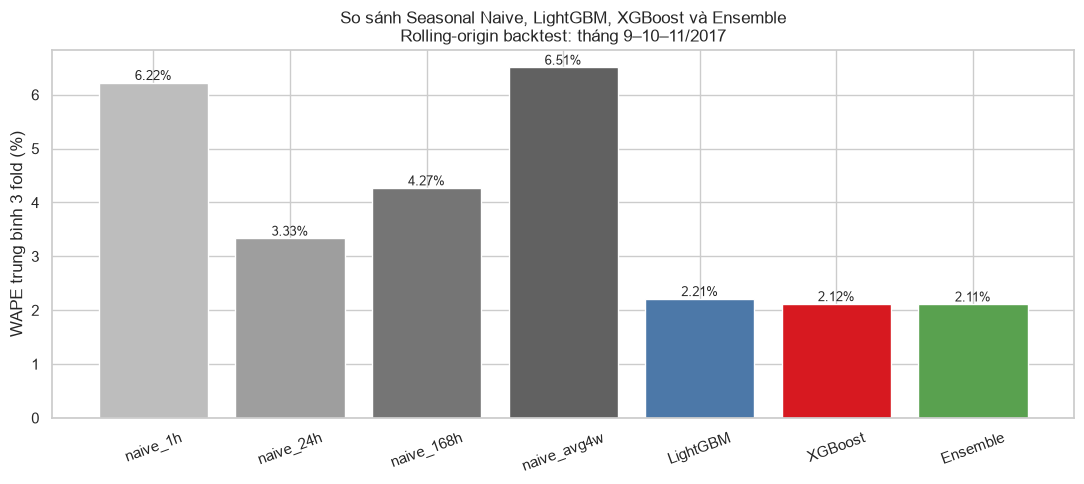

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(model_order))
values = summary_avg.loc[model_order, "WAPE_%"]

ax.bar(
    x,
    values,
    color=[MODEL_COLORS.get(model, "#999999") for model in model_order],
)
ax.set_xticks(x)
ax.set_xticklabels(model_order, rotation=20)
ax.set_ylabel("Mean WAPE across 3 folds (%)")
ax.set_title(
    "Comparison of Seasonal Naive, LightGBM, XGBoost, and the ensemble\n"
    "Rolling-origin backtest: Sep–Oct–Nov 2017"
)

for xi, value in zip(x, values):
    ax.text(xi, value + 0.05, f"{value:.2f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

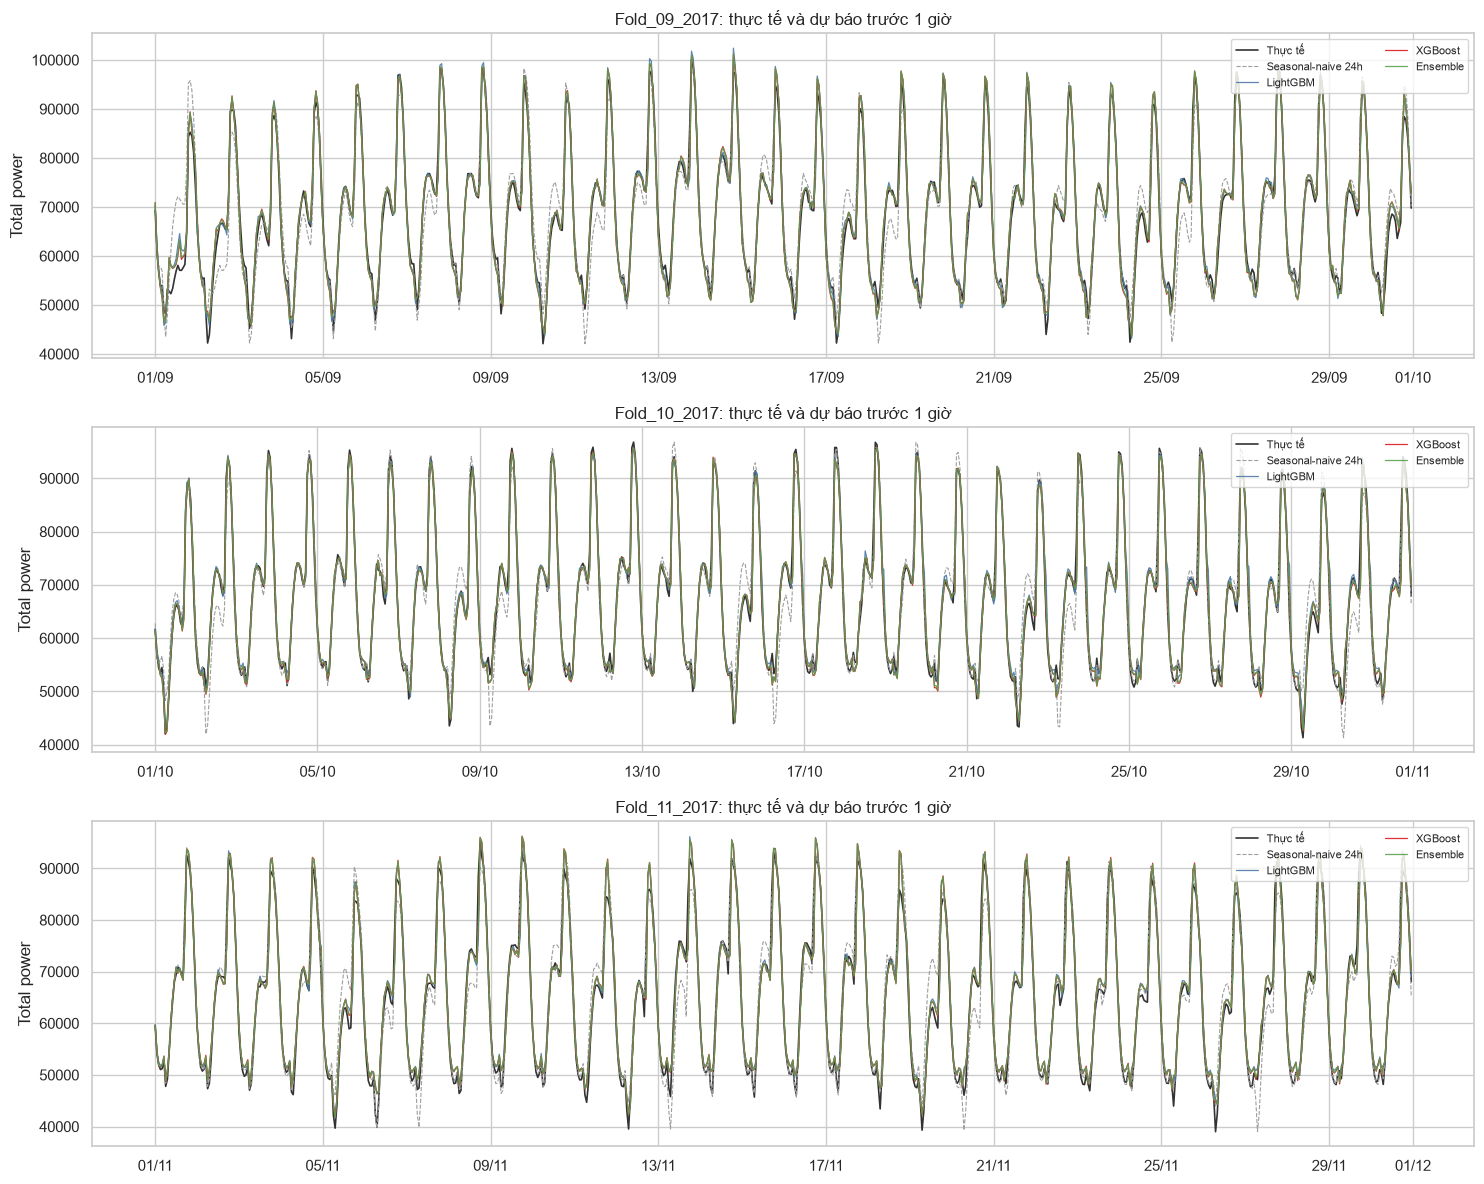

In [ ]:
fig, axes = plt.subplots(
    len(fold_defs),
    1,
    figsize=(15, 4 * len(fold_defs)),
    sharey=False,
)

for ax, (fold_name, val_start, val_end) in zip(axes, fold_defs):
    segment = backtest_predictions.loc[
        backtest_predictions["fold"] == fold_name
    ]

    ax.plot(
        segment["forecast_time"],
        segment[TARGET_COL],
        color="#333333",
        linewidth=1.2,
        label="Actual",
    )
    ax.plot(
        segment["forecast_time"],
        segment["naive_24h"],
        color=MODEL_COLORS["naive_24h"],
        linewidth=0.8,
        linestyle="--",
        label="Seasonal-naive 24h",
    )
    for model_name in ["LightGBM", "XGBoost", "Ensemble"]:
        ax.plot(
            segment["forecast_time"],
            segment[model_name],
            color=MODEL_COLORS[model_name],
            linewidth=0.9,
            alpha=0.9,
            label=model_name,
        )

    ax.set_title(f"{fold_name}: actual and 1-hour-ahead forecast")
    ax.set_ylabel("Total power")
    ax.legend(loc="upper right", fontsize=8, ncol=2)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))

plt.tight_layout()
plt.show()

In [ ]:
print("Trees chosen by early stopping in each fold:")
display(model_fit_info_df)

fold_winners = fold_pivot.loc[["LightGBM", "XGBoost", "Ensemble"]].idxmin()
print("\nModel with the lowest WAPE in each fold:")
display(fold_winners.to_frame("best_model"))

print(
    "\nSelection rule: prefer a lower mean WAPE, then also check "
    "WAPE_std, MASE, and bias. The ensemble is selected only if it uses both models "
    f"and improves by at least {MIN_ENSEMBLE_RELATIVE_GAIN_PCT:.1f}% relative "
    "versus the best single model."
)
print(f"Conclusion before opening the holdout: {selected_model_name}")

Trees chosen by early stopping in each fold:


,fold,model,best_n_estimators
0,Fold_09_2017,LightGBM,373
1,Fold_09_2017,XGBoost,998
2,Fold_10_2017,LightGBM,283
3,Fold_10_2017,XGBoost,2721
4,Fold_11_2017,LightGBM,470
5,Fold_11_2017,XGBoost,2721



Model with the lowest WAPE in each fold:


,best_model
fold,
Fold_09_2017,Ensemble
Fold_10_2017,XGBoost
Fold_11_2017,Ensemble



Selection rule: prefer a lower mean WAPE, then check WAPE_std, MASE, and bias. The ensemble is selected only if it uses both models and improves WAPE by at least 0.5% relative to the best single model.
Conclusion before opening the holdout: XGBoost


## 16. Evaluation on the final holdout (December 2017)

The final holdout is evaluated only once, after:

- The feature pipeline is fixed.
- LightGBM and XGBoost have been compared on the three rolling folds.
- The ensemble weights, and the rule for whether to use the ensemble, are fixed.

Both models are refit on all development data from January–November 2017. The December ensemble uses the weights chosen from the September–November out-of-fold predictions. It is not re-optimized on the holdout.

In [ ]:
y_holdout = final_holdout_df[TARGET_COL].to_numpy()
naive_holdout = naive_forecasts(final_holdout_df["forecast_time"])
naive_24h_mae_holdout = regression_metrics(
    y_holdout,
    naive_holdout["naive_24h"],
)["MAE"]

holdout_results = []
holdout_pred_table = final_holdout_df[["forecast_time", TARGET_COL]].copy()

for name, pred in naive_holdout.items():
    holdout_results.append({
        "model": name,
        "n": len(y_holdout),
        **regression_metrics(y_holdout, pred, naive_24h_mae_holdout),
    })
    holdout_pred_table[name] = pred

lgbm_holdout_pred, lgbm_final_model, lgbm_final_info = fit_predict_lightgbm(
    development_df,
    final_holdout_df,
)
holdout_results.append({
    "model": "LightGBM",
    "n": len(y_holdout),
    **regression_metrics(
        y_holdout,
        lgbm_holdout_pred,
        naive_24h_mae_holdout,
    ),
})
holdout_pred_table["LightGBM"] = lgbm_holdout_pred

xgb_holdout_pred, xgb_final_model, xgb_final_info = fit_predict_xgboost(
    development_df,
    final_holdout_df,
)
holdout_results.append({
    "model": "XGBoost",
    "n": len(y_holdout),
    **regression_metrics(
        y_holdout,
        xgb_holdout_pred,
        naive_24h_mae_holdout,
    ),
})
holdout_pred_table["XGBoost"] = xgb_holdout_pred

ensemble_holdout_pred = (
    BEST_LGBM_WEIGHT * lgbm_holdout_pred
    + BEST_XGB_WEIGHT * xgb_holdout_pred
)
holdout_results.append({
    "model": "Ensemble",
    "n": len(y_holdout),
    **regression_metrics(
        y_holdout,
        ensemble_holdout_pred,
        naive_24h_mae_holdout,
    ),
})
holdout_pred_table["Ensemble"] = ensemble_holdout_pred

holdout_results_df = (
    pd.DataFrame(holdout_results)
    .set_index("model")
    .reindex(model_order)
)

holdout_candidate_winner = holdout_results_df["WAPE_%"].idxmin()

print("Final holdout results — December 2017:")
display(holdout_results_df.round(3))
print(
    f"Final tree count — LightGBM: {lgbm_final_info['best_n_estimators']}, "
    f"XGBoost: {xgb_final_info['best_n_estimators']}"
)
print(f"Model with the lowest WAPE on the holdout: {holdout_candidate_winner}")
print(
    f"Model selected before the holdout was opened: {selected_model_name}. "
    "The holdout is used only to check generalization. It is not used to reselect the model."
)

Final holdout results — December 2017:


,n,MAE,RMSE,WAPE_%,Bias,MASE
model,,,,,,
naive_1h,720,"3,946.57","5,475.33",6.19,-2.64,1.91
naive_24h,720,"2,071.54","3,296.29",3.25,51.16,1.00
naive_168h,720,"1,775.39","2,619.85",2.79,-60.45,0.86
naive_avg4w,720,"1,621.02","2,359.69",2.54,397.17,0.78
LightGBM,720,"1,062.51","1,448.50",1.67,381.94,0.51
XGBoost,720,"1,027.28","1,343.41",1.61,263.40,0.50
Ensemble,720,"1,024.44","1,347.22",1.61,287.11,0.49


Final tree count — LightGBM: 591, XGBoost: 2708
Model with the lowest WAPE on the holdout: Ensemble
Model selected before the holdout was opened: XGBoost. The holdout is used only to check generalization. It is not used to reselect the model.


## 16.1 Save the trained models

Writes the fitted LightGBM and XGBoost models, ensemble weights, and feature list to `notebooks/models/final_forecast_models.pkl`. These objects otherwise exist only in this kernel.

In [ ]:
import pickle
from pathlib import Path

model_dir = Path("notebooks/models") if Path("notebooks").is_dir() else Path("models")
model_dir.mkdir(parents=True, exist_ok=True)
model_path = model_dir / "final_forecast_models.pkl"

with model_path.open("wb") as model_file:
    pickle.dump(
    {
        "lightgbm": lgbm_final_model,
        "xgboost": xgb_final_model,
        "weight_lightgbm": float(BEST_LGBM_WEIGHT),
        "weight_xgboost": float(BEST_XGB_WEIGHT),
        "feature_columns": list(feature_columns),
        "selected_model": selected_model_name,
    },
        model_file,
    )
print(f"Saved trained models to {model_path.resolve()}")
print(f"Selected model: {selected_model_name}")


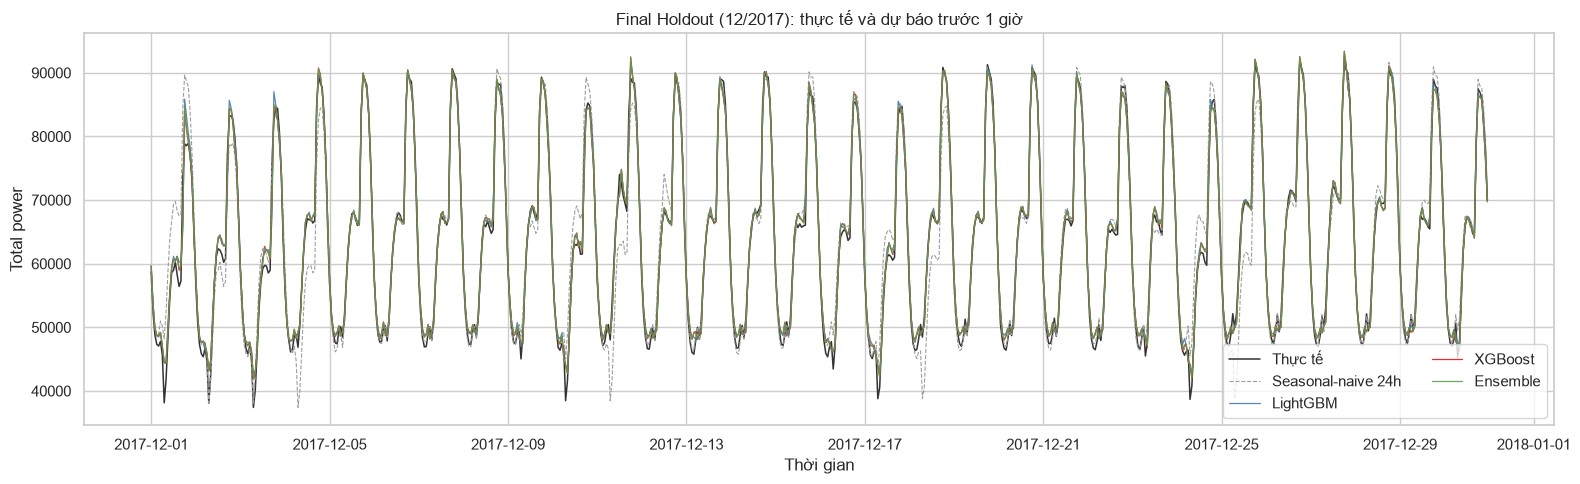

In [ ]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(
    holdout_pred_table["forecast_time"],
    holdout_pred_table[TARGET_COL],
    color="#333333",
    linewidth=1.1,
    label="Actual",
)
ax.plot(
    holdout_pred_table["forecast_time"],
    holdout_pred_table["naive_24h"],
    color=MODEL_COLORS["naive_24h"],
    linestyle="--",
    linewidth=0.8,
    label="Seasonal-naive 24h",
)

for model_name in ["LightGBM", "XGBoost", "Ensemble"]:
    ax.plot(
        holdout_pred_table["forecast_time"],
        holdout_pred_table[model_name],
        color=MODEL_COLORS[model_name],
        linewidth=0.9,
        alpha=0.9,
        label=model_name,
    )

ax.set_title("Final holdout (Dec 2017): actual and 1-hour-ahead forecast")
ax.set_xlabel("Time")
ax.set_ylabel("Total power")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 17. Peak-demand analysis: fixed capacity threshold and reserve-margin scenarios

**Rule:** the capacity threshold is computed **once, from the earliest training data** (January–August 2017, before the first validation fold) and then **held fixed** for every validation fold and the final holdout. It is not recomputed per period, so the threshold cannot look ahead.

Three reference thresholds: **P90, P95, and P99** of hourly total load in the earliest training period.

In [ ]:
BASE_THRESHOLD_END = pd.Timestamp("2017-09-01")
base_train_for_threshold = df_model[df_model["forecast_time"] < BASE_THRESHOLD_END]

capacity_thresholds = base_train_for_threshold[TARGET_COL].quantile([0.90, 0.95, 0.99])
capacity_thresholds.index = ["P90", "P95", "P99"]

print(f"Fixed capacity threshold, computed from {base_train_for_threshold['forecast_time'].min()} → "
      f"{base_train_for_threshold['forecast_time'].max()} ({len(base_train_for_threshold):,} hours):")
display(capacity_thresholds.to_frame("threshold"))

# Pool every out-of-sample forecast: 3 backtest folds (Sep–Nov 2017) plus the final holdout (Dec 2017).
# This gives enough observations for the breach analysis, and it is still outside the training sample used to set the threshold.
pooled_oos = pd.concat([
    backtest_predictions.assign(period="backtest_fold"),
    holdout_pred_table.assign(period="final_holdout"),
], ignore_index=True).sort_values("forecast_time").reset_index(drop=True)

for thr_name, thr_val in capacity_thresholds.items():
    n_breach = int((pooled_oos[TARGET_COL] > thr_val).sum())
    print(f"{thr_name} = {thr_val:,.0f}: {n_breach} breach hours in the full out-of-sample period (09–12/2017, {len(pooled_oos)} hours)")

Fixed capacity threshold, computed from 2017-01-08 01:00:00 → 2017-08-31 23:00:00 (5,663 hours):


,threshold
P90,"97,298.94"
P95,"103,168.76"
P99,"119,843.93"


P90 = 97,299: 9 breach hours in the full out-of-sample period (09–12/2017, 2904 hours)
P95 = 103,169: 0 breach hours in the full out-of-sample period (09–12/2017, 2904 hours)
P99 = 119,844: 0 breach hours in the full out-of-sample period (09–12/2017, 2904 hours)


**Note on sample size:** the threshold is computed on a training period that includes summer (July–August, the highest peak of the year), so very few hours in Sep–Dec 2017 breach it, especially at P95 and P99. This is **not a model failure**. It is a real property of the data: capacity planned for the summer peak has a large safety margin in autumn and winter. Read the recall and precision below together with the bootstrap confidence interval, not as a point number alone.

In [ ]:
def breach_confusion(y_true, y_pred, threshold):
    actual_breach = y_true > threshold
    pred_breach = y_pred > threshold
    tp = int((actual_breach & pred_breach).sum())
    fn = int((actual_breach & ~pred_breach).sum())
    fp = int((~actual_breach & pred_breach).sum())
    tn = int((~actual_breach & ~pred_breach).sum())
    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    return {
        "n_actual_breach": int(actual_breach.sum()),
        "n_pred_breach": int(pred_breach.sum()),
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
        "recall": recall,
        "precision": precision,
    }


def bootstrap_recall_ci(y_true, y_pred, threshold, n_boot=1000, seed=42):
    '''Day-block bootstrap for the breach-recall confidence interval.'''
    rng = np.random.default_rng(seed)
    actual_breach = y_true > threshold
    if actual_breach.sum() == 0:
        return (np.nan, np.nan)

    n_days = len(y_true) // 24
    if n_days < 2:
        return (np.nan, np.nan)

    day_idx = np.arange(n_days)
    recalls = []
    for _ in range(n_boot):
        sampled_days = rng.choice(day_idx, size=n_days, replace=True)
        selected = np.concatenate([
            np.arange(day * 24, day * 24 + 24)
            for day in sampled_days
        ])
        selected = selected[selected < len(y_true)]
        yt = y_true[selected]
        yp = y_pred[selected]
        actual = yt > threshold
        if actual.sum() == 0:
            continue
        predicted = yp > threshold
        recalls.append((actual & predicted).sum() / actual.sum())

    if not recalls:
        return (np.nan, np.nan)
    return (
        float(np.percentile(recalls, 2.5)),
        float(np.percentile(recalls, 97.5)),
    )


BEST_MODEL_COL = selected_model_name
print(
    f"Point-forecast model used for the peak analysis: {BEST_MODEL_COL} "
    "(chosen from the rolling backtest, not from the holdout)"
)

y_pooled = pooled_oos[TARGET_COL].to_numpy()
pred_pooled = pooled_oos[BEST_MODEL_COL].to_numpy()

breach_rows = []
for threshold_name, threshold_value in capacity_thresholds.items():
    confusion = breach_confusion(y_pooled, pred_pooled, threshold_value)
    ci_low, ci_high = bootstrap_recall_ci(
        y_pooled,
        pred_pooled,
        threshold_value,
    )
    breach_rows.append({
        "threshold": threshold_name,
        "value": threshold_value,
        **confusion,
        "recall_CI95_low": ci_low,
        "recall_CI95_high": ci_high,
    })

breach_table = pd.DataFrame(breach_rows)
display(breach_table.round(3))

Point-forecast model used for the peak analysis: XGBoost (chosen from the rolling backtest, not from the holdout)


,threshold,value,n_actual_breach,n_pred_breach,TP,FN,FP,TN,recall,precision,recall_CI95_low,recall_CI95_high
0,P90,"97,298.95",9,16,9,0,7,2888,1.00,0.56,1.00,1.00
1,P95,"103,168.76",0,0,0,0,0,2904,NaN,NaN,NaN,NaN
2,P99,"119,843.93",0,0,0,0,0,2904,NaN,NaN,NaN,NaN


### 17.1 Reserve-margin scenarios

Instead of alerting only when the **point forecast** crosses the threshold, operators usually add a reserve margin before the comparison. That is safer, but it also calls more reserve and costs more. The matrix below compares several margins at the P90 threshold, the only threshold with enough breach hours for a meaningful analysis in Sep–Dec 2017.

In [ ]:
RESERVE_MARGINS = [0.00, 0.05, 0.10, 0.15, 0.20]
threshold_for_scenarios = capacity_thresholds["P90"]

scenario_rows = []
for margin in RESERVE_MARGINS:
    required_capacity_pred = pred_pooled * (1 + margin)
    conf = breach_confusion(y_pooled, required_capacity_pred, threshold_for_scenarios)
    extra_reserve_hours = conf["FP"]  # hours when reserve was called but was not actually needed (extra cost)
    scenario_rows.append({
        "reserve_margin": f"{margin:.0%}",
        "n_actual_breach": conf["n_actual_breach"],
        "n_flagged": conf["n_pred_breach"],
        "TP_correctly_flagged": conf["TP"],
        "FN_missed": conf["FN"],
        "FP_over_provision": conf["FP"],
        "recall": conf["recall"],
        "precision": conf["precision"],
    })

scenario_table = pd.DataFrame(scenario_rows)
print(f"Capacity threshold used: P90 = {threshold_for_scenarios:,.0f} (fixed, computed from Jan–Aug 2017)")
display(scenario_table.round(3))

Capacity threshold used: P90 = 97,299 (fixed, computed from Jan–Aug 2017)


,reserve_margin,n_actual_breach,n_flagged,TP_correctly_flagged,FN_missed,FP_over_provision,recall,precision
0,0%,9,16,9,0,7,1.00,0.56
1,5%,9,129,9,0,120,1.00,0.07
2,10%,9,266,9,0,257,1.00,0.03
3,15%,9,391,9,0,382,1.00,0.02
4,20%,9,485,9,0,476,1.00,0.02


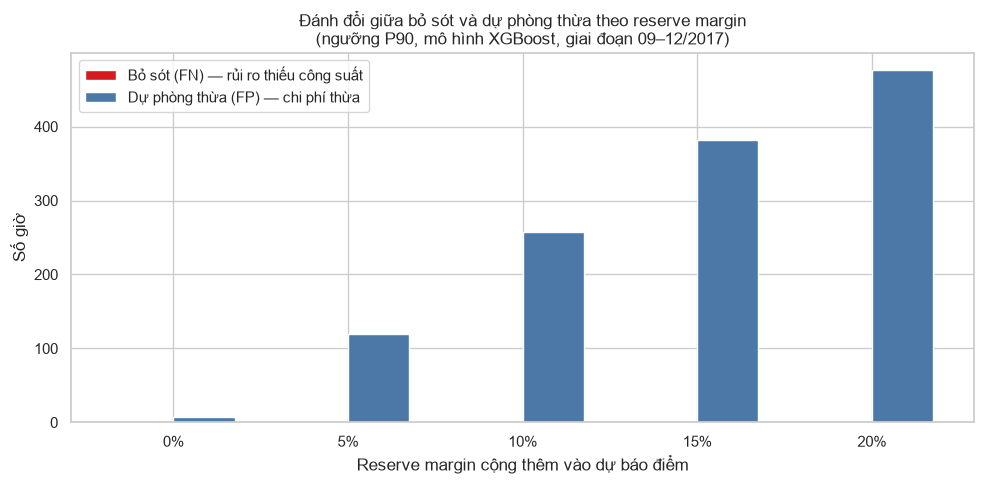

Interpretation: a 0% margin alerts on the raw point forecast. That has the highest chance of a miss, but it does not pay for unused reserve.
A larger margin raises recall (fewer misses) but also increases the hours of reserve that were not actually needed (FP).
The right margin depends on the operator's cost ratio of being short of capacity versus holding extra reserve (Cu:Co) —
Real cost data is required to choose the optimal margin.


In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(len(RESERVE_MARGINS))
width = 0.35

ax1.bar(x - width/2, scenario_table["FN_missed"], width, color=VC_RED, label="Missed (FN) — capacity-shortfall risk")
ax1.bar(x + width/2, scenario_table["FP_over_provision"], width, color=VC_BLUE, label="Extra reserve (FP) — extra cost")
ax1.set_xticks(x)
ax1.set_xticklabels(scenario_table["reserve_margin"])
ax1.set_xlabel("Reserve margin added to the point forecast")
ax1.set_ylabel("Hours")
ax1.set_title(f"Trade-off between misses and extra reserve by reserve margin\n(P90 threshold, model {BEST_MODEL_COL}, Sep–Dec 2017)")
ax1.legend()
plt.tight_layout()
plt.show()

print("Interpretation: a 0% margin alerts on the raw point forecast. That has the highest chance of a miss, but it does not pay for unused reserve.")
print("A larger margin raises recall (fewer misses) but also increases the hours of reserve that were not actually needed (FP).")
print("The right margin depends on the operator's cost ratio of being short of capacity versus holding extra reserve (Cu:Co) —")
print("Real cost data is required to choose the optimal margin.")

### 17.2 Daily peak magnitude and timing errors

For each day in the out-of-sample period (Sep–Dec 2017), compare the **actual daily peak** (value and hour) with the **forecast daily peak** from the 1-hour-ahead forecast path of the best model.

In [ ]:
daily_peak = pooled_oos.copy()
daily_peak["date"] = daily_peak["forecast_time"].dt.date
daily_peak["hour"] = daily_peak["forecast_time"].dt.hour

def _daily_peak_stats(g):
    actual_idx = g[TARGET_COL].idxmax()
    forecast_idx = g[BEST_MODEL_COL].idxmax()
    return pd.Series({
        "actual_peak": g.loc[actual_idx, TARGET_COL],
        "actual_peak_hour": g.loc[actual_idx, "hour"],
        "forecast_peak": g.loc[forecast_idx, BEST_MODEL_COL],
        "forecast_peak_hour": g.loc[forecast_idx, "hour"],
    })

daily_peak_stats = daily_peak.groupby("date").apply(_daily_peak_stats)
daily_peak_stats["magnitude_error"] = daily_peak_stats["forecast_peak"] - daily_peak_stats["actual_peak"]
daily_peak_stats["magnitude_pct_error"] = daily_peak_stats["magnitude_error"] / daily_peak_stats["actual_peak"] * 100

hour_diff = (daily_peak_stats["forecast_peak_hour"] - daily_peak_stats["actual_peak_hour"]).abs()
daily_peak_stats["timing_error_hours"] = np.minimum(hour_diff, 24 - hour_diff)

print("Daily peak-error summary (Sep–Dec 2017, n =", len(daily_peak_stats), "days):")
peak_error_summary = pd.Series({
    "Peak magnitude MAE": daily_peak_stats["magnitude_error"].abs().mean(),
    "Peak magnitude RMSE": np.sqrt((daily_peak_stats["magnitude_error"] ** 2).mean()),
    "Peak magnitude bias (forecast − actual)": daily_peak_stats["magnitude_error"].mean(),
    "Peak magnitude MAPE (%)": daily_peak_stats["magnitude_pct_error"].abs().mean(),
    "Mean peak-timing error (hours)": daily_peak_stats["timing_error_hours"].mean(),
    "Share of days with peak timing within ±1 hour": (daily_peak_stats["timing_error_hours"] <= 1).mean(),
})
display(peak_error_summary.round(2).to_frame("Value"))
display(daily_peak_stats.head(10).round(2))

Daily peak-error summary (Sep–Dec 2017, n = 121 days):


,Value
Peak magnitude MAE,"1,606.88"
Peak magnitude RMSE,"2,160.24"
Peak magnitude bias (forecast − actual),"1,127.55"
Peak magnitude MAPE (%),1.79
Mean peak-timing error (hours),0.38
Share of days with peak timing within ±1 hour,0.98


,actual_peak,actual_peak_hour,forecast_peak,forecast_peak_hour,magnitude_error,magnitude_pct_error,timing_error_hours
date,,,,,,,
2017-09-01,"85,259.76",20.00,"89,415.81",20.00,"4,156.05",4.87,0.00
2017-09-02,"89,787.17",20.00,"92,676.02",20.00,"2,888.86",3.22,0.00
2017-09-03,"88,634.80",20.00,"91,312.02",20.00,"2,677.22",3.02,0.00
2017-09-04,"91,369.70",20.00,"93,724.77",20.00,"2,355.07",2.58,0.00
2017-09-05,"92,927.74",19.00,"95,042.77",20.00,"2,115.04",2.28,1.00
2017-09-06,"97,044.34",20.00,"96,674.72",20.00,-369.62,-0.38,0.00
2017-09-07,"98,128.92",19.00,"98,521.45",19.00,392.52,0.40,0.00
2017-09-08,"98,269.41",19.00,"98,467.73",20.00,198.32,0.20,1.00
2017-09-09,"95,306.08",19.00,"96,838.77",19.00,"1,532.68",1.61,0.00


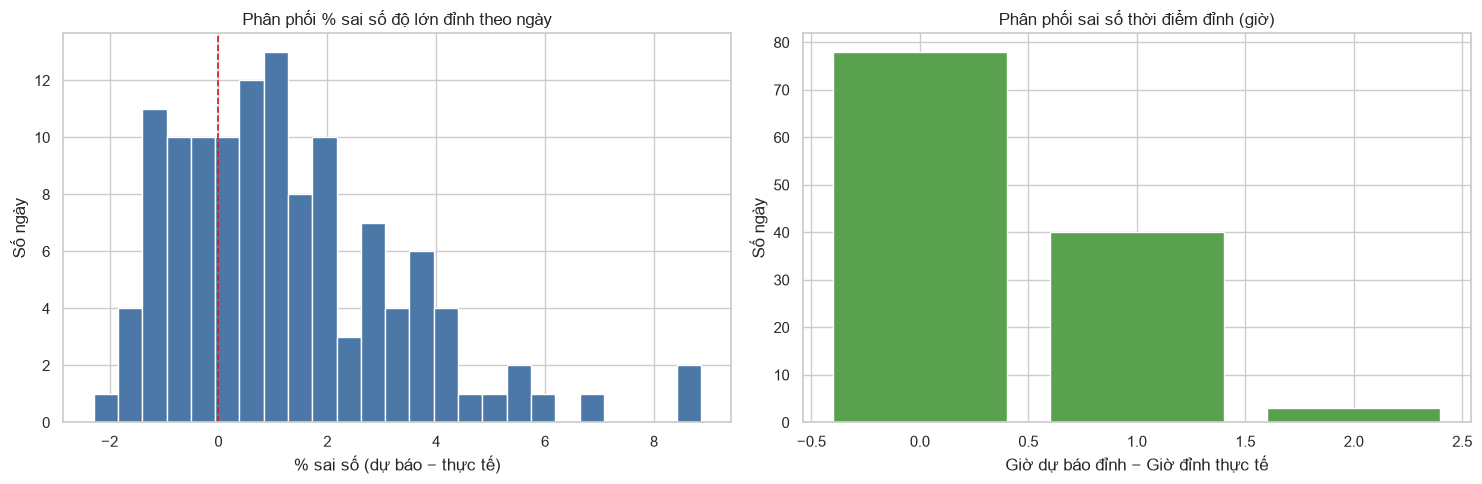

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(daily_peak_stats["magnitude_pct_error"], bins=25, color=VC_BLUE, edgecolor="white")
axes[0].axvline(0, color=VC_RED, linewidth=1.2, linestyle="--")
axes[0].set_title("Distribution of daily peak-magnitude percent error")
axes[0].set_xlabel("% error (forecast − actual)")
axes[0].set_ylabel("Number of days")

timing_counts = daily_peak_stats["timing_error_hours"].value_counts().sort_index()
axes[1].bar(timing_counts.index, timing_counts.values, color=VC_GREEN)
axes[1].set_title("Distribution of peak-timing error (hours)")
axes[1].set_xlabel("Forecast peak hour − actual peak hour")
axes[1].set_ylabel("Number of days")

plt.tight_layout()
plt.show()

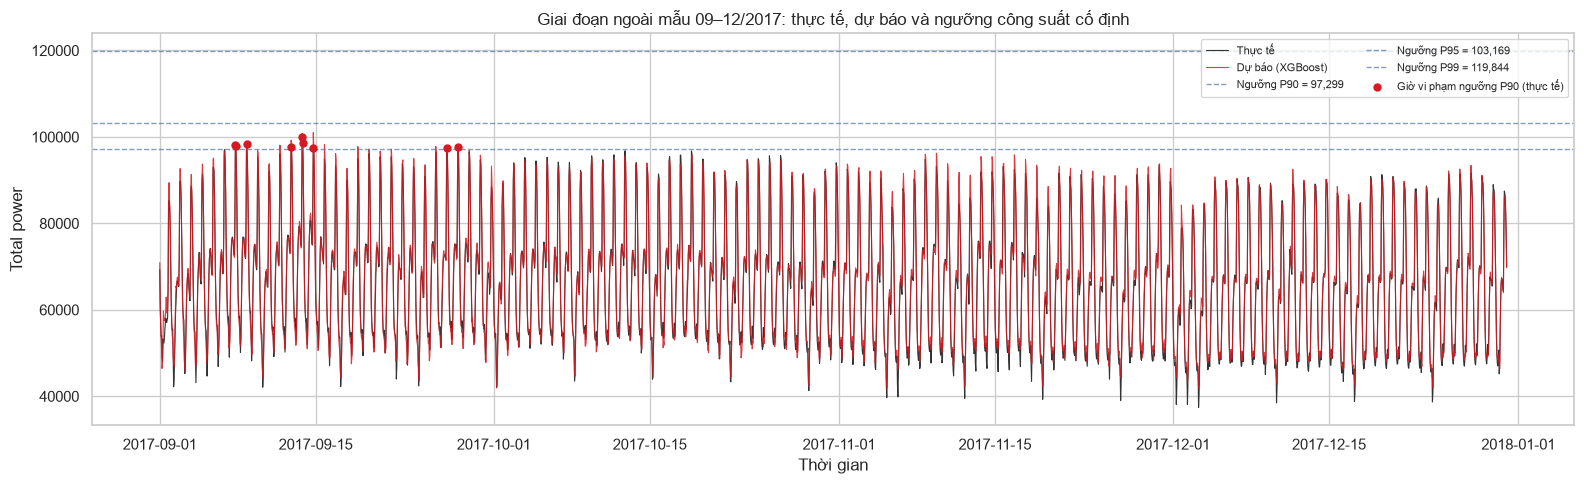

In [ ]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(pooled_oos["forecast_time"], pooled_oos[TARGET_COL], color="#333333", linewidth=0.8, label="Actual")
ax.plot(pooled_oos["forecast_time"], pooled_oos[BEST_MODEL_COL], color=MODEL_COLORS[BEST_MODEL_COL],
        linewidth=0.8, alpha=0.85, label=f"Forecast ({BEST_MODEL_COL})")

for thr_name, thr_val in capacity_thresholds.items():
    ax.axhline(thr_val, linestyle="--", linewidth=1, alpha=0.7, label=f"Threshold {thr_name} = {thr_val:,.0f}")

breach_mask = pooled_oos[TARGET_COL] > capacity_thresholds["P90"]
ax.scatter(pooled_oos.loc[breach_mask, "forecast_time"], pooled_oos.loc[breach_mask, TARGET_COL],
           color=VC_RED, s=25, zorder=5, label="Hours above the P90 threshold (actual)")

ax.set_title("Out-of-sample period Sep–Dec 2017: actual, forecast, and the fixed capacity threshold")
ax.set_xlabel("Time")
ax.set_ylabel("Total power")
ax.legend(loc="upper right", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 18. Results summary and model-selection rule

The notebook selects the model with the following procedure:

1. Seasonal-naive 24h is the required benchmark; a good model needs MASE < 1 in a stable way.
2. LightGBM, XGBoost, and the ensemble are compared by mean WAPE on the three rolling folds.
3. `WAPE_std`, RMSE, MASE, and bias are used to check stability and the risk of forecasting too low or too high.
4. The ensemble is selected only if it truly uses both models and the gain over the best single model is clear. If the gain is tiny, prefer the simpler model.
5. The December final holdout only checks generalization. Do not change the choice just because another model happens to win on the holdout.
6. The model chosen on the backtest is used consistently for the peak-demand and reserve-margin analysis.

The specific conclusions below are filled from the notebook results, so comments are not hardcoded before the models have been run.

In [ ]:
candidate_comparison = pd.DataFrame({
    "Backtest_WAPE_mean": summary_avg.loc[
        model_order, "WAPE_%"
    ],
    "Backtest_WAPE_std": summary_avg.loc[
        model_order, "WAPE_std"
    ],
    "Backtest_MASE_mean": summary_avg.loc[
        model_order, "MASE"
    ],
    "Backtest_Bias_mean": summary_avg.loc[
        model_order, "Bias"
    ],
    "Holdout_WAPE": holdout_results_df.loc[
        model_order, "WAPE_%"
    ],
    "Holdout_MASE": holdout_results_df.loc[
        model_order, "MASE"
    ],
})

display(candidate_comparison.round(3))

backtest_winner = candidate_comparison["Backtest_WAPE_mean"].idxmin()
holdout_winner = candidate_comparison["Holdout_WAPE"].idxmin()

print(f"Model with the lowest backtest WAPE: {backtest_winner}")
print(f"Model with the lowest holdout WAPE: {holdout_winner}")
print(f"Model recommended by the pre-fixed rule: {selected_model_name}")

if selected_model_name == holdout_winner:
    print("The rolling-backtest choice is confirmed on the final holdout.")
else:
    print(
        "Note: the holdout winner differs from the backtest choice. "
        "Do not reselect the model from December alone. Collect more "
        "out-of-sample periods before changing the decision."
    )

if summary_avg.loc[selected_model_name, "MASE"] < 1:
    print("The selected model beats seasonal-naive 24h on mean MASE.")
else:
    print(
        "The selected model does not beat seasonal-naive 24h on MASE. "
        "In that case, prefer the simple baseline and review the features and the model."
    )

,Backtest_WAPE_mean,Backtest_WAPE_std,Backtest_MASE_mean,Backtest_Bias_mean,Holdout_WAPE,Holdout_MASE
model,,,,,,
naive_1h,6.22,0.04,1.90,5.24,6.19,1.91
naive_24h,3.33,0.53,1.00,38.79,3.25,1.00
naive_168h,4.27,2.48,1.23,911.23,2.79,0.86
naive_avg4w,6.51,5.59,1.82,"3,504.11",2.54,0.78
LightGBM,2.21,0.30,0.67,285.60,1.67,0.51
XGBoost,2.12,0.38,0.64,135.82,1.61,0.50
Ensemble,2.11,0.37,0.64,165.78,1.61,0.49


Model with the lowest backtest WAPE: Ensemble
Model with the lowest holdout WAPE: Ensemble
Model recommended by the pre-fixed rule: XGBoost
Note: the holdout winner differs from the backtest choice. Do not reselect the model from December alone. Collect more out-of-sample periods before changing the decision.
The selected model beats seasonal-naive 24h on mean MASE.


## Export evaluation for the web model tab


In [ ]:
import json

importance = pd.Series(
    lgbm_final_model.feature_importances_, index=feature_columns, name="importance"
).sort_values(ascending=False)
eval_payload = {
    "selected_model": selected_model_name,
    "weight_lightgbm": float(BEST_LGBM_WEIGHT),
    "weight_xgboost": float(BEST_XGB_WEIGHT),
    "feature_columns": list(feature_columns),
    "feature_importance": [
        {"feature": name, "importance": float(value)}
        for name, value in importance.items()
    ],
    "fold_wape": fold_pivot.reset_index().to_dict(orient="records"),
    "summary": (
        summary_avg.reset_index()
        .rename(columns={"WAPE_%": "WAPE_pct"})
        .to_dict(orient="records")
    ),
    "holdout_metrics": (
        holdout_results_df.reset_index()
        .rename(columns={"WAPE_%": "WAPE_pct"})
        .to_dict(orient="records")
    ),
    "holdout_series": [
        {
            "forecast_time": pd.Timestamp(row.forecast_time).isoformat(),
            "actual": float(row.target_t_plus_1),
            "lightgbm": float(row.LightGBM),
            "xgboost": float(row.XGBoost),
            "ensemble": float(row.Ensemble),
        }
        for row in holdout_pred_table.itertuples(index=False)
    ],
    "capacity_p90": float(capacity_thresholds["P90"]),
    "reserve_margins": scenario_table.to_dict(orient="records"),
    "comparison": (
        candidate_comparison.reset_index()
        .rename(columns={
            "Backtest_WAPE_mean": "backtest_wape_mean",
            "Backtest_WAPE_std": "backtest_wape_std",
            "Backtest_MASE_mean": "backtest_mase_mean",
            "Backtest_Bias_mean": "backtest_bias_mean",
            "Holdout_WAPE": "holdout_wape",
            "Holdout_MASE": "holdout_mase",
        })
        .to_dict(orient="records")
    ),
    "selection_note": (
        f"Model selected before the holdout was opened: {selected_model_name}."
    ),
}
eval_path = Path("output") / "model_evaluation.json"
eval_path.write_text(json.dumps(eval_payload))
print(f"Saved {eval_path}")
